# HW2 — Problem 1: Selective Memory with SSM (50%)

Complete the five model TODOs in the next code cell. Save your completed work as **hw2_1_315511079.ipynb**, including outputs, plots, tables and discussion.

## Getting started
1. Join the [course Kaggle competition](https://www.kaggle.com/t/8c17aaa8718948559394446f43ea896c).
2. Download `train.jsonl`, `val.jsonl`, and `test.jsonl`. Locally or in Colab, place them in `data/`; on Kaggle, attach the competition data using the notebook's Input panel.
3. Use a Python environment with **PyTorch** and **Matplotlib** installed.
4. Complete `basic_init`, `basic_forward`, `gate_init`, `gate_compute`, and `gate_forward`. Then execute the cells in order.

This notebook contains the fixed vocabulary, loader, training loop, checkpoint saving, plots, benchmark and CSV writer. You do not need separate utility Python files.

The next cell creates `hw2_1.py` automatically in the working directory. **Edit TODOs in this notebook cell**: rerunning it overwrites that generated file. Model TODOs intentionally raise `NotImplementedError` until completed.

The task requirements and grading rules are in the assignment PDF. Use only the provided training data for optimization and validation data for model selection.

---
**Student ID:** 315511079 (Kaggle team name = 315511079)

Run on Google Colab (NVIDIA A100-SXM4-40GB). Data: `train.jsonl`, `val.jsonl`, `test.jsonl` in `data/`.


## Colab setup
By default everything is written to the local Colab disk. Optional: set `USE_DRIVE = True` to mount Drive and makes `MyDrive/hw2_1_work` the working directory, so `runs/` (checkpoints, per-epoch resume files) and outputs persist. After a disconnect just *Run all* again: finished runs are skipped and an interrupted Q4 run resumes from its last epoch. Put the three JSONL files (or the competition zip) in `MyDrive/hw2_1_work/` or in `MyDrive/hw2_1_work/data/`.

In [1]:
import zipfile, glob, os, shutil
USE_DRIVE = False   # True = save runs/ to Google Drive so a disconnect can resume (needs Drive authorisation)
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        WORK = "/content/drive/MyDrive/hw2_1_work"
        os.makedirs(WORK, exist_ok=True)
        for f in glob.glob("/content/*.zip") + glob.glob("/content/*.jsonl"):
            shutil.copy(f, WORK)
        os.chdir(WORK)
    except Exception as e:
        print("Drive not available, using the local Colab disk instead:", e)
print("Working directory:", os.getcwd())
os.makedirs("data", exist_ok=True)
for f in glob.glob("*.jsonl"):
    shutil.move(f, os.path.join("data", f))
for z in glob.glob("*.zip"):
    with zipfile.ZipFile(z) as f:
        for name in f.namelist():
            base = os.path.basename(name)
            if base in ("train.jsonl", "val.jsonl", "test.jsonl"):
                with open(os.path.join("data", base), "wb") as out:
                    out.write(f.read(name))
print(sorted(os.listdir("data")))


Working directory: /content
['test.jsonl', 'train.jsonl', 'val.jsonl']


In [2]:
%%writefile hw2_1.py
"""Provided training/evaluation utilities. Model inputs are tokens only."""
import argparse
import csv
import json
import math
import platform
import random
import time
from collections import defaultdict
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

def fixed_vocab():
    tokens = ['PAD','BOS','SEP','STORE','NOISE','QUERY','ANSWER'] + [f'K{i}' for i in range(32)] + [f'V{i}' for i in range(32)]
    return {token: i for i, token in enumerate(tokens)}

def seed_all(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

class MemoryDataset(Dataset):
    def __init__(self, path, vocab, limit=0):
        self.rows = [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]
        if limit:
            self.rows = self.rows[:limit]
        if not self.rows:
            raise ValueError(f'Empty dataset: {path}')
        self.ids = [[vocab[t] for t in row['tokens']] for row in self.rows]
        self.labels = [int(row['answer'][1:]) if 'answer' in row else -100 for row in self.rows]
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        return self.ids[i], self.labels[i], self.rows[i]

def collate(samples):
    lengths = torch.tensor([len(x[0]) for x in samples], dtype=torch.long)
    # PAD is ID 0 in the fixed vocabulary.
    tokens = torch.zeros(len(samples), int(lengths.max()), dtype=torch.long)
    for i,(ids,_,_) in enumerate(samples):
        tokens[i,:len(ids)] = torch.tensor(ids)
    return tokens, lengths, torch.tensor([x[1] for x in samples]), [x[2] for x in samples]

def loader(path, vocab, batch_size, shuffle=False, limit=0):
    return DataLoader(MemoryDataset(path,vocab,limit),batch_size=batch_size,shuffle=shuffle,collate_fn=collate,num_workers=0)

class SSMBlock(nn.Module):
    def __init__(self, ssm, d, dropout):
        super().__init__()
        self.ssm=ssm
        self.norm=nn.LayerNorm(d)
        self.act=nn.GELU()
        self.dropout=nn.Dropout(dropout)
    def forward(self,x,return_gates=False):
        y,g=self.ssm(self.norm(x),return_gates=return_gates)
        return x+self.dropout(self.act(y)),g

class MemoryModel(nn.Module):
    def __init__(self, config, basic_class, gated_class):
        super().__init__()
        d,n=config['d'],config['n']
        self.embedding=nn.Embedding(71,d,padding_idx=0)
        layers=[]
        for _ in range(config['layers']):
            ssm=basic_class(d,n) if config['model']=='basic' else gated_class(d,n)
            layers.append(SSMBlock(ssm,d,config['dropout']))
        self.blocks=nn.ModuleList(layers)
        self.norm=nn.LayerNorm(d)
        self.head=nn.Linear(d,32)
    def forward(self,tokens,lengths,return_gates=False):
        x=self.embedding(tokens)
        gates=[]
        for block in self.blocks:
            x,g=block(x,return_gates)
            gates.append(g)
        # Only valid ANSWER representations reach the prediction head.
        last=self.norm(x)[torch.arange(tokens.size(0),device=tokens.device),lengths-1]
        return self.head(last),gates

def sync(device):
    if device.type=='cuda': torch.cuda.synchronize(device)

def on_device(batch,device):
    tokens,lengths,labels,rows=batch
    return tokens.to(device),lengths.to(device),labels.to(device),rows

@torch.no_grad()
def evaluate(model,batches,device,keep=False):
    model.eval()
    total_loss=correct=total=0
    predictions=[]
    for batch in batches:
        tokens,lengths,labels,rows=on_device(batch,device)
        logits,_=model(tokens,lengths)
        pred=logits.argmax(-1)
        valid=labels.ne(-100)
        if valid.any():
            total_loss+=nn.functional.cross_entropy(logits[valid],labels[valid],reduction='sum').item()
            correct+=(pred[valid]==labels[valid]).sum().item()
            total+=valid.sum().item()
        if keep:
            for row,p in zip(rows,pred.cpu().tolist()):
                predictions.append(dict(id=row['id'],prediction=f'V{p}',answer=row.get('answer'),group=row.get('group','all'),tokens=row['tokens']))
    return {'loss':total_loss/total if total else None,'accuracy':correct/total if total else None,'count':total},predictions

def save_json(path,obj):
    Path(path).write_text(json.dumps(obj,indent=2)+'\n')

def plot_history(history,path):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(6,4))
    ax.plot([r['epoch'] for r in history],[r['train_loss'] for r in history],label='Training')
    ax.plot([r['epoch'] for r in history],[r['val_loss'] for r in history],label='Validation')
    ax.set(xlabel='Epoch',ylabel='Cross-entropy loss'); ax.legend(); fig.tight_layout(); fig.savefig(path,dpi=150); plt.close(fig)

def train(args,basic,gated):
    seed_all(args.seed)
    device=resolve_device(args.device)
    config={k:getattr(args,k) for k in ['model','d','n','layers','dropout']}
    model=MemoryModel(config,basic,gated).to(device)
    effective=sum(p.numel() for p in model.parameters() if p.requires_grad)
    if effective>=1000000: raise ValueError('Effective trainable parameter count must be below 1,000,000.')
    vocab=fixed_vocab()
    tr=loader(args.data/'train.jsonl',vocab,args.batch_size,True,args.limit_train)
    va=loader(args.data/'val.jsonl',vocab,args.batch_size,False,args.limit_val)
    optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=args.lr,weight_decay=args.weight_decay)
    out=args.out; out.mkdir(parents=True,exist_ok=True)
    best=(-1.,float('-inf')); history=[]
    if device.type=='cuda': torch.cuda.reset_peak_memory_stats(device)
    peak_training=0
    environment={'torch':torch.__version__,'python':platform.python_version(),'device':str(device),'device_name':torch.cuda.get_device_name(device) if device.type=='cuda' else platform.processor(),'precision':'float32','threads':torch.get_num_threads()}
    for epoch in range(1,args.epochs+1):
        model.train(); total=loss_sum=0
        if device.type=='cuda': torch.cuda.reset_peak_memory_stats(device)
        sync(device); start=time.perf_counter()
        for batch in tr:
            tokens,lengths,labels,_=on_device(batch,device)
            optimizer.zero_grad(set_to_none=True)
            logits,_=model(tokens,lengths)
            loss=nn.functional.cross_entropy(logits,labels)
            if not torch.isfinite(loss): raise RuntimeError('Non-finite loss')
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
            total+=len(labels); loss_sum+=loss.item()*len(labels)
        sync(device); elapsed=time.perf_counter()-start
        if device.type=='cuda': peak_training=max(peak_training,torch.cuda.max_memory_allocated(device))
        sync(device); start=time.perf_counter(); metrics,_=evaluate(model,va,device); sync(device)
        record=dict(epoch=epoch,train_loss=loss_sum/total,val_loss=metrics['loss'],val_accuracy=metrics['accuracy'],train_seconds=elapsed,val_seconds=time.perf_counter()-start)
        history.append(record); print(json.dumps(record),flush=True)
        rank=(metrics['accuracy'],-metrics['loss'])
        if rank>best:
            best=rank
            # No optimizer or executable Python objects in the checkpoint.
            torch.save({'state_dict':model.state_dict(),'config':config,'vocab':vocab,'epoch':epoch,'validation':metrics,'seed':args.seed},out/'best.pt')
        save_json(out/'history.json',history)
    checkpoint=torch.load(out/'best.pt',map_location=device,weights_only=True)
    model.load_state_dict(checkpoint['state_dict']); model.eval()
    inference=benchmark(model,va,device)
    validation, predictions=evaluate(model,va,device,True)
    save_json(out/'failure_examples.json',[row for row in predictions if row['prediction']!=row['answer']][:3])
    plot_history(history,out/'learning_curves.png')
    save_json(out/'run_config.json',{**vars_serializable(args),'environment':environment})
    save_json(out/'training_summary.json',{'effective_trainable_parameters':effective,'total_parameters':sum(p.numel() for p in model.parameters()),'mean_train_seconds_per_epoch':sum(h['train_seconds'] for h in history)/len(history),'inference':inference,'best_validation_accuracy':best[0],'peak_training_allocated_bytes':peak_training if device.type=='cuda' else None,'note':'CPU memory is not GPU allocated memory; no GPU estimate is supplied. Validation excluded from epoch training time.'})

def vars_serializable(args):
    return {k:str(v) if isinstance(v,Path) else v for k,v in vars(args).items()}

def resolve_device(name):
    if name=='auto': name='cuda' if torch.cuda.is_available() else 'cpu'
    device=torch.device(name)
    if device.type=='cuda' and not torch.cuda.is_available(): raise RuntimeError('CUDA requested but unavailable')
    return device

def restore(args,basic,gated):
    device=resolve_device(args.device)
    checkpoint=torch.load(args.checkpoint,map_location=device,weights_only=True)
    model=MemoryModel(checkpoint['config'],basic,gated).to(device)
    model.load_state_dict(checkpoint['state_dict']); model.eval()
    return model,checkpoint['vocab'],device

def predict(args,basic,gated):
    model,vocab,device=restore(args,basic,gated)
    batches=loader(args.input,vocab,args.batch_size)
    _,rows=evaluate(model,batches,device,True)
    args.output.parent.mkdir(parents=True,exist_ok=True)
    with args.output.open('w',newline='') as f:
        w=csv.writer(f); w.writerow(['id','answer']); w.writerows((r['id'],r['prediction']) for r in rows)
    print(f'Wrote {len(rows)} predictions to {args.output}')

@torch.no_grad()
def benchmark(model,batches,device):
    # Time forward only on a fixed padded batch, with copies excluded.
    tokens,lengths,_,_=on_device(next(iter(batches)),device)
    for _ in range(3): model(tokens,lengths)
    sync(device); start=time.perf_counter()
    for _ in range(10): model(tokens,lengths)
    sync(device); seconds=(time.perf_counter()-start)/10
    return dict(forward_batch_seconds=seconds,forward_samples_per_second=tokens.size(0)/seconds,batch_size=tokens.size(0),padded_length=tokens.size(1),timing_scope='10 repeated forwards after 3 warmups; data transfer excluded')


def diag_scan(lam, u):
    """Causal linear recurrence h_t = lam_t * h_{t-1} + u_t with h_0 = 0.

    lam, u: [batch, length, N].  Returns h: [batch, length, N].
    Hillis-Steele parallel prefix scan over the time axis (log2(L) steps).
    It only multiplies decays in (0, 1], so it is numerically stable, and each
    output position t depends on positions <= t only (causal).  A fresh scan is
    run on every forward call, so no state is carried between samples/batches.
    """
    A, h = lam, u
    length = u.size(1)
    offset = 1
    while offset < length:
        # combine element t with element t-offset: (A_t, h_t) o (A_s, h_s)
        h = torch.cat([h[:, :offset], A[:, offset:] * h[:, :-offset] + h[:, offset:]], dim=1)
        A = torch.cat([A[:, :offset], A[:, offset:] * A[:, :-offset]], dim=1)
        offset *= 2
    return h

def reference_loop(lam, u):
    """Slow step-by-step reference used only by the sanity-check cell."""
    h = torch.zeros_like(u[:, 0])
    out = []
    for t in range(u.size(1)):
        h = lam[:, t] * h + u[:, t]
        out.append(h)
    return torch.stack(out, dim=1)

class DiagonalSSM(nn.Module):
    def __init__(self, d, n, a_min=0.5, a_max=0.99):
        super().__init__()
        self.d, self.n = d, n
        # TODO: basic_init
        # a = sigmoid(theta_a) is initialised evenly over [a_min, a_max] (default 0.5-0.99,
        # the suggested spread). B, C, D: Gaussian with std 1/sqrt(fan_in); no biases.
        a = torch.linspace(a_min, a_max, n)
        self.theta_a = nn.Parameter(torch.log(a) - torch.log1p(-a))   # logit(a)
        self.B = nn.Parameter(torch.randn(n, d) / math.sqrt(d))        # [N, d]
        self.C = nn.Parameter(torch.randn(d, n) / math.sqrt(n))        # [d, N]
        self.D = nn.Parameter(torch.randn(d, d) / math.sqrt(d))        # [d, d]

    def forward(self, x, return_gates=False):
        """x: [batch,length,d]; return (y [batch,length,d], gates or None)."""
        # TODO: basic_forward
        a = torch.sigmoid(self.theta_a)                 # [N], in (0, 1)
        u = x @ self.B.t()                              # B x_t        -> [batch, length, N]
        h = diag_scan(a.expand_as(u), u)                # h_t = a*h_{t-1} + B x_t, h_0 = 0
        y = h @ self.C.t() + x @ self.D.t()             # C h_t + D x_t -> [batch, length, d]
        return y, None

class GatedDiagonalSSM(DiagonalSSM):
    def __init__(self, d, n, a_min=0.5, a_max=0.99):
        super().__init__(d, n, a_min=a_min, a_max=a_max)
        # TODO: gate_init
        # Same rule as B (std 1/sqrt(d)); gate bias zero -> g = 0.5 at initialisation.
        self.W_g = nn.Parameter(torch.randn(n, d) / math.sqrt(d))      # [N, d]
        self.b_g = nn.Parameter(torch.zeros(n))                        # [N]

    def forward(self, x, return_gates=False):
        # TODO: gate_compute
        g = torch.sigmoid(x @ self.W_g.t() + self.b_g)  # g_t = sigma(W_g x_t + b_g) -> [batch, length, N]
        # TODO: gate_forward
        a = torch.sigmoid(self.theta_a)                 # [N]
        bx = x @ self.B.t()                             # B x_t
        # h_t = (1-g_t)*h_{t-1} + g_t*(a*h_{t-1} + B x_t)
        #     = (1 - g_t*(1-a)) * h_{t-1} + g_t * B x_t
        lam = 1 - g * (1 - a)
        h = diag_scan(lam, g * bx)
        y = h @ self.C.t() + x @ self.D.t()
        return y, (g if return_gates else None)


def run_cli(basic,gated):
    parser=argparse.ArgumentParser()
    parser.add_argument('--threads',type=int,default=2)
    sub=parser.add_subparsers(dest='command',required=True)
    t=sub.add_parser('train')
    t.add_argument('--model',choices=['basic','gated'],required=True)
    t.add_argument('--data',type=Path,default=Path('data'));t.add_argument('--out',type=Path,required=True)
    for name,value in [('d',64),('n',64),('layers',2),('epochs',10),('batch-size',64),('seed',42),('limit-train',0),('limit-val',0)]:t.add_argument('--'+name,type=int,default=value)
    t.add_argument('--dropout',type=float,default=.1);t.add_argument('--lr',type=float,default=.001);t.add_argument('--weight-decay',type=float,default=.01);t.add_argument('--device',default='auto')
    q=sub.add_parser('predict');q.add_argument('--checkpoint',type=Path,required=True);q.add_argument('--input',type=Path,required=True);q.add_argument('--output',type=Path,required=True);q.add_argument('--batch-size',type=int,default=64);q.add_argument('--device',default='auto')
    args=parser.parse_args();torch.set_num_threads(args.threads)
    if args.command=='train':train(args,basic,gated)
    else:predict(args,basic,gated)

if __name__=='__main__':run_cli(DiagonalSSM,GatedDiagonalSSM)


Writing hw2_1.py


## Data and output directories

Set `DATA_DIR` to the folder containing all three JSONL files. This cell tries `data/`, the current directory, and attached Kaggle input folders. If more than one matching dataset is found, select the course dataset manually. The working directory must be writable.


In [3]:
from pathlib import Path
import subprocess, sys, json

DATA_DIR = Path("data")  # Change this if your files are elsewhere.
REQUIRED_FILES = ("train.jsonl", "val.jsonl", "test.jsonl")
def has_data(folder):
    return all((folder / name).is_file() for name in REQUIRED_FILES)

if not has_data(DATA_DIR):
    candidates = [Path(".")] if has_data(Path(".")) else []
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates += [p.parent for p in kaggle_input.rglob("train.jsonl")
                       if has_data(p.parent)]
    candidates = sorted(set(p.resolve() for p in candidates))
    if len(candidates) == 1:
        DATA_DIR = candidates[0]
    else:
        raise FileNotFoundError(
            "Set DATA_DIR to the course data folder containing "
            + ", ".join(REQUIRED_FILES)
            + f". Matching folders found: {candidates}"
        )
print("Data directory:", DATA_DIR.resolve())


def run_script(cmd):
    """Run a script and stream its stdout+stderr into the notebook, so errors are visible."""
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="", flush=True)
    if proc.wait() != 0:
        raise RuntimeError(f"Command failed (exit {proc.returncode}); see the error printed above: {cmd}")

def run(*args):
    run_script([sys.executable, "hw2_1.py", *map(str, args)])



Data directory: /content/data


In [4]:
# Hardware / software versions (reported for reproducibility)
import torch, platform, matplotlib
print("Python    :", platform.python_version())
print("PyTorch   :", torch.__version__, "| CUDA:", torch.version.cuda)
print("Matplotlib:", matplotlib.__version__)
print("Device    :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor())


Python    : 3.13.16
PyTorch   : 2.11.0+cu130 | CUDA: 13.0
Matplotlib: 3.10.0
Device    : NVIDIA A100-SXM4-40GB


## Correctness checks of the SSM implementation
1. The parallel scan output equals a literal step-by-step loop of the PDF equations (basic and gated).
2. Causality: changing tokens after position t does not change outputs at positions ≤ t.
3. Right padding does not change the prediction read at the final valid ANSWER position.
4. Two forward passes give identical outputs (no hidden state carried across calls).


In [5]:
import importlib, torch, math
import hw2_1; importlib.reload(hw2_1)
from hw2_1 import DiagonalSSM, GatedDiagonalSSM, MemoryModel
torch.manual_seed(0)
x = torch.randn(3, 17, 64)
basic, gated = DiagonalSSM(64, 64), GatedDiagonalSSM(64, 64)
with torch.no_grad():
    # literal loops of the PDF equations
    a = torch.sigmoid(basic.theta_a); h = torch.zeros(3, 64); ys = []
    for t in range(17):
        h = a * h + x[:, t] @ basic.B.T
        ys.append(h @ basic.C.T + x[:, t] @ basic.D.T)
    print("basic max |scan - loop| =", (basic(x)[0] - torch.stack(ys, 1)).abs().max().item())
    a = torch.sigmoid(gated.theta_a); h = torch.zeros(3, 64); ys = []
    for t in range(17):
        h_tilde = a * h + x[:, t] @ gated.B.T
        g = torch.sigmoid(x[:, t] @ gated.W_g.T + gated.b_g)
        h = (1 - g) * h + g * h_tilde
        ys.append(h @ gated.C.T + x[:, t] @ gated.D.T)
    print("gated max |scan - loop| =", (gated(x)[0] - torch.stack(ys, 1)).abs().max().item())
    # causality
    x2 = x.clone(); x2[:, 10:] = torch.randn_like(x2[:, 10:])
    print("causal (outputs before t=10 unchanged):", torch.allclose(gated(x)[0][:, :10], gated(x2)[0][:, :10], atol=1e-6))
    # padding + final-position selection + statelessness
    m = MemoryModel(dict(model="gated", d=64, n=64, layers=2, dropout=0.1), DiagonalSSM, GatedDiagonalSSM).eval()
    toks = torch.randint(1, 71, (2, 20)); lens = torch.tensor([20, 13]); toks[1, 13:] = 0
    full = m(toks, lens)[0]; alone = m(toks[1:, :13], lens[1:])[0]
    print("padding-safe ANSWER selection:", torch.allclose(full[1], alone[0], atol=1e-5))
    print("stateless across calls:", torch.equal(m(toks, lens)[0], m(toks, lens)[0]))
for name in ("basic", "gated"):
    mm = MemoryModel(dict(model=name, d=64, n=64, layers=2, dropout=0.1), DiagonalSSM, GatedDiagonalSSM)
    print(f"{name}: trainable parameters = {sum(p.numel() for p in mm.parameters() if p.requires_grad):,}")


basic max |scan - loop| = 1.0728836059570312e-06
gated max |scan - loop| = 9.5367431640625e-07
causal (outputs before t=10 unchanged): True
padding-safe ANSWER selection: True
stateless across calls: True
basic: trainable parameters = 31,712
gated: trainable parameters = 40,032


## Small pipeline check — not a formal result

In [6]:
run("train","--model","gated","--data",DATA_DIR,"--out","runs/smoke","--epochs",1,"--limit-train",256,"--limit-val",128)

{"epoch": 1, "train_loss": 3.6257930994033813, "val_loss": 3.5219582319259644, "val_accuracy": 0.0234375, "train_seconds": 0.9195880309999893, "val_seconds": 0.06057410700003629}


## Q1 and Q2 — identical training settings

In [7]:
# Q1 + Q2 with identical settings (provided training loop, 10 epochs each). Skipped if already finished.
for name in ["basic","gated"]:
    if Path(f"runs/{name}/training_summary.json").exists():
        print(name, "already trained -> skipped"); continue
    run("train","--model",name,"--data",DATA_DIR,"--out",f"runs/{name}")


{"epoch": 1, "train_loss": 3.4904036966959637, "val_loss": 3.454680938720703, "val_accuracy": 0.04466666666666667, "train_seconds": 2.6524338440000292, "val_seconds": 0.13071120899996913}
{"epoch": 2, "train_loss": 3.40140531539917, "val_loss": 3.361838282267253, "val_accuracy": 0.06533333333333333, "train_seconds": 2.188950351000017, "val_seconds": 0.10667448899999954}
{"epoch": 3, "train_loss": 3.3247221819559734, "val_loss": 3.3427345428466797, "val_accuracy": 0.07733333333333334, "train_seconds": 2.2026422499999967, "val_seconds": 0.10722902600002726}
{"epoch": 4, "train_loss": 3.266492826461792, "val_loss": 3.328299102783203, "val_accuracy": 0.08266666666666667, "train_seconds": 2.1992896259999952, "val_seconds": 0.10734186299998782}
{"epoch": 5, "train_loss": 3.21173880704244, "val_loss": 3.259451395670573, "val_accuracy": 0.09866666666666667, "train_seconds": 2.188460322000026, "val_seconds": 0.1070549120000237}
{"epoch": 6, "train_loss": 3.1380795351664226, "val_loss": 3.216482

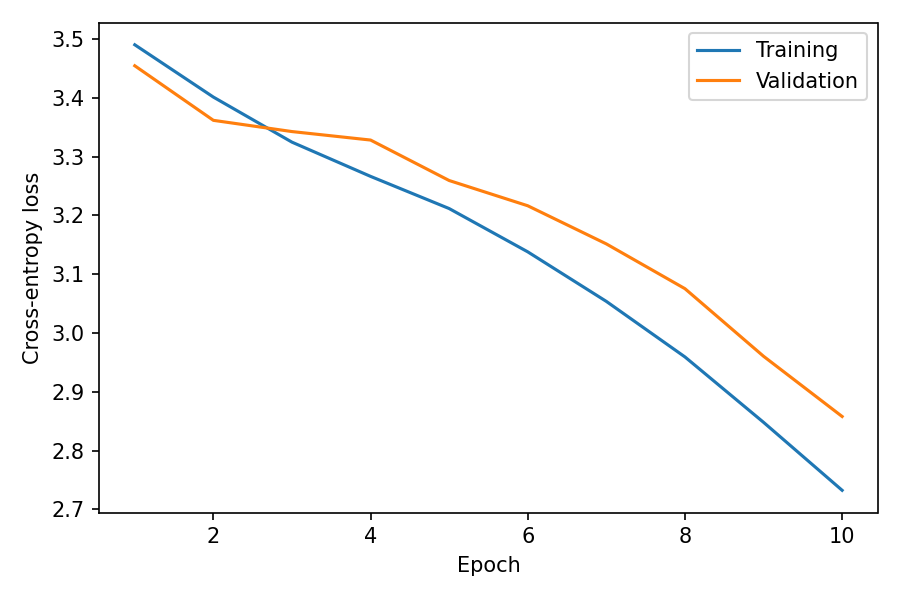

basic: best validation accuracy = 0.1913 at epoch 10 (val loss 2.8580)
   epoch  1 | train loss 3.4904 | val loss 3.4547 | val acc 0.0447 | train 2.7s
   epoch  2 | train loss 3.4014 | val loss 3.3618 | val acc 0.0653 | train 2.2s
   epoch  3 | train loss 3.3247 | val loss 3.3427 | val acc 0.0773 | train 2.2s
   epoch  4 | train loss 3.2665 | val loss 3.3283 | val acc 0.0827 | train 2.2s
   epoch  5 | train loss 3.2117 | val loss 3.2595 | val acc 0.0987 | train 2.2s
   epoch  6 | train loss 3.1381 | val loss 3.2165 | val acc 0.1147 | train 2.2s
   epoch  7 | train loss 3.0538 | val loss 3.1516 | val acc 0.1373 | train 2.2s
   epoch  8 | train loss 2.9593 | val loss 3.0754 | val acc 0.1547 | train 2.2s
   epoch  9 | train loss 2.8480 | val loss 2.9604 | val acc 0.1773 | train 2.2s
   epoch 10 | train loss 2.7324 | val loss 2.8580 | val acc 0.1913 | train 2.2s
Failures: [{'id': 'val_000001', 'prediction': 'V29', 'answer': 'V19', 'group': 'all', 'tokens': ['BOS', 'NOISE', 'K17', 'V26', 'S

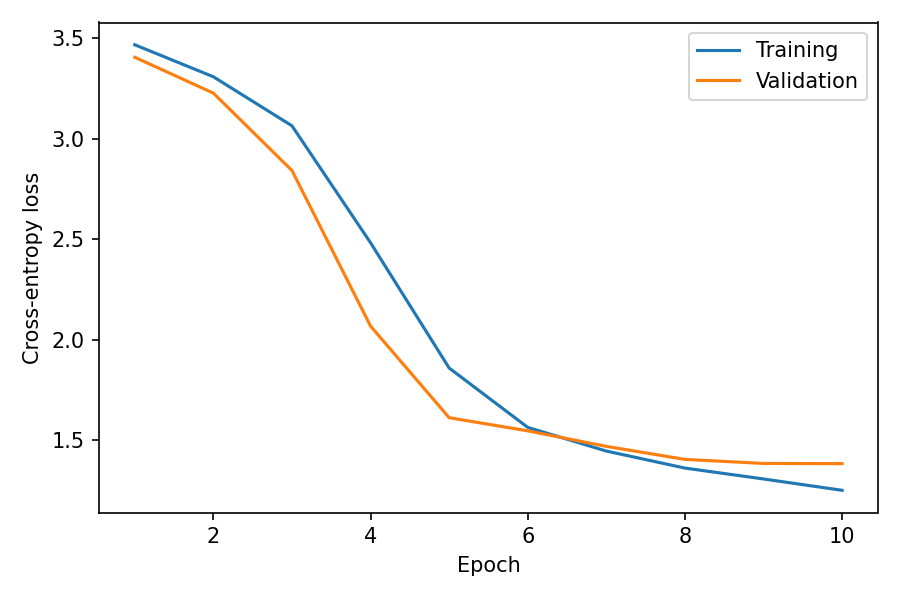

gated: best validation accuracy = 0.4060 at epoch 8 (val loss 1.4038)
   epoch  1 | train loss 3.4680 | val loss 3.4057 | val acc 0.0680 | train 2.9s
   epoch  2 | train loss 3.3086 | val loss 3.2273 | val acc 0.1027 | train 2.4s
   epoch  3 | train loss 3.0645 | val loss 2.8418 | val acc 0.1880 | train 2.4s
   epoch  4 | train loss 2.4822 | val loss 2.0673 | val acc 0.3373 | train 2.4s
   epoch  5 | train loss 1.8586 | val loss 1.6114 | val acc 0.3860 | train 2.4s
   epoch  6 | train loss 1.5631 | val loss 1.5459 | val acc 0.3740 | train 2.4s
   epoch  7 | train loss 1.4453 | val loss 1.4686 | val acc 0.3887 | train 2.4s
   epoch  8 | train loss 1.3606 | val loss 1.4038 | val acc 0.4060 | train 2.4s
   epoch  9 | train loss 1.3063 | val loss 1.3837 | val acc 0.3880 | train 2.4s
   epoch 10 | train loss 1.2499 | val loss 1.3826 | val acc 0.4007 | train 2.4s
Failures: [{'id': 'val_000001', 'prediction': 'V21', 'answer': 'V19', 'group': 'all', 'tokens': ['BOS', 'NOISE', 'K17', 'V26', 'SE

In [8]:
from IPython.display import Image, display
results = {}
for name in ["basic","gated"]:
    display(Image(filename=f"runs/{name}/learning_curves.png"))
    summ = json.loads(Path(f"runs/{name}/training_summary.json").read_text())
    hist = json.loads(Path(f"runs/{name}/history.json").read_text())
    best = max(hist, key=lambda r: (r["val_accuracy"], -r["val_loss"]))
    results[name] = dict(summary=summ, history=hist, best=best)
    print(f"{name}: best validation accuracy = {best['val_accuracy']:.4f} at epoch {best['epoch']} (val loss {best['val_loss']:.4f})")
    for r in hist:
        print(f"   epoch {r['epoch']:2d} | train loss {r['train_loss']:.4f} | val loss {r['val_loss']:.4f} | val acc {r['val_accuracy']:.4f} | train {r['train_seconds']:.1f}s")
    print("Failures:", json.loads(Path(f"runs/{name}/failure_examples.json").read_text()))


## Q3 — comparison
Table filled from `training_summary.json`. Inference = first validation batch (64 samples, padded), 3 warm-up + 10 timed forward passes in `eval()` / `no_grad`, with `torch.cuda.synchronize()` before and after timing; transfers excluded. Training time = mean of the training-only part of each epoch (validation excluded).

In [9]:
# Q3(a) comparison table, filled automatically from the saved run summaries
import pandas as pd
cfg_env = json.loads(Path("runs/gated/run_config.json").read_text())["environment"]
def row(name):
    s = results[name]["summary"]; inf = s["inference"]
    mem = s["peak_training_allocated_bytes"]
    return {"Trainable parameters": f'{s["effective_trainable_parameters"]:,}',
            "Validation accuracy": f'{s["best_validation_accuracy"]:.4f} (epoch {results[name]["best"]["epoch"]})',
            "Training time (seconds/epoch)": f'{s["mean_train_seconds_per_epoch"]:.2f}',
            "Inference throughput (samples/s)": f'{inf["forward_samples_per_second"]:,.0f}',
            "Peak GPU allocated memory (MiB)": "N/A" if mem is None else f"{mem/2**20:.1f}"}
table = pd.DataFrame({"Basic SSM": row("basic"), "Gated SSM": row("gated")})
display(table)
inf = results["gated"]["summary"]["inference"]
print("Environment:", cfg_env)
print(f"Inference scope: {inf['timing_scope']}; batch size {inf['batch_size']}, padded length {inf['padded_length']} (first validation batch)")


,Basic SSM,Gated SSM
Trainable parameters,"31,712","40,032"
Validation accuracy,0.1913 (epoch 10),0.4060 (epoch 8)
Training time (seconds/epoch),2.24,2.47
Inference throughput (samples/s),"30,696","27,129"
Peak GPU allocated memory (MiB),92.5,104.8


Environment: {'torch': '2.11.0+cu130', 'python': '3.13.16', 'device': 'cuda', 'device_name': 'NVIDIA A100-SXM4-40GB', 'precision': 'float32', 'threads': 2}
Inference scope: 10 repeated forwards after 3 warmups; data transfer excluded; batch size 64, padded length 124 (first validation batch)


In [10]:
# Representative failure cases (first validation errors of each selected checkpoint)
def show_failure(r):
    t = r["tokens"]; recs = [t[1+4*i:5+4*i] for i in range((len(t)-4)//4)]
    q = t[-2]
    rel = [" ".join(x[:3]) for x in recs if x[1] == q]
    print(f'  {r["id"]}: query {q}, gold {r["answer"]}, predicted {r["prediction"]}, records={len(recs)}, '
          f'stores={sum(x[0]=="STORE" for x in recs)}, records with query key: {rel}')
for name in ["basic", "gated"]:
    print(name)
    for r in json.loads(Path(f"runs/{name}/failure_examples.json").read_text()):
        show_failure(r)


basic
  val_000001: query K20, gold V19, predicted V29, records=27, stores=2, records with query key: ['NOISE K20 V17', 'STORE K20 V19']
  val_000002: query K23, gold V23, predicted V1, records=23, stores=4, records with query key: ['NOISE K23 V18', 'STORE K23 V23']
  val_000003: query K1, gold V17, predicted V15, records=24, stores=3, records with query key: ['NOISE K1 V12', 'STORE K1 V17']
gated
  val_000001: query K20, gold V19, predicted V21, records=27, stores=2, records with query key: ['NOISE K20 V17', 'STORE K20 V19']
  val_000002: query K23, gold V23, predicted V17, records=23, stores=4, records with query key: ['NOISE K23 V18', 'STORE K23 V23']
  val_000006: query K5, gold V21, predicted V4, records=26, stores=3, records with query key: ['NOISE K5 V3', 'NOISE K5 V25', 'STORE K5 V21']


## Q4(a) — improvement and validation results (3 points)

Modify at least one factor, such as state dimension, depth, learning rate, training schedule, or prediction head. Compare validation accuracy, parameter count and runtime with your original gated model.

For Q4 only, prediction-head changes and task-consistent augmentation derived solely from `train.jsonl` are allowed, with labels updated consistently. Examples include consistent key/value renaming or querying another valid stored key in a training example. The head may combine the final valid ANSWER representation with the observed query-key embedding. Retain the specified SSM updates and token-only inputs; keep the complete model below 1,000,000 trainable parameters. Never train or augment with validation/test examples. Q1–3 must retain the prescribed backbone and matched settings.


In [11]:
%%writefile hw2_1_q4.py
"""Q4 improvement: wider/deeper gated SSM + query-key head + task-consistent augmentation.

Everything here re-uses the provided utilities and the *same* GatedDiagonalSSM class
from hw2_1.py (the SSM update equations are unchanged).  Inputs are token IDs only.
Training uses data/train.jsonl only; checkpoints are selected on data/val.jsonl only.
"""
import argparse
import copy
import csv
import json
import math
import platform
import random
import time
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

from hw2_1 import (GatedDiagonalSSM, SSMBlock, MemoryDataset, collate, loader, fixed_vocab,
                   seed_all, evaluate, benchmark, sync, on_device, resolve_device,
                   save_json, plot_history)

# ----------------------------------------------------------------------------------
# Task-consistent augmentation of TRAINING samples only
# ----------------------------------------------------------------------------------
def augment_tokens(tokens, rng):
    """Return (new_tokens, new_answer_index) for one training prompt.

    1. Random permutation of key names K0..K31 (applied consistently to every record and query).
    2. Random permutation of value names V0..V31 (applied consistently; the label is mapped too).
    3. Random shuffle of record order (the task states record order is random).
    4. Re-sample the query key uniformly from the valid STORE keys and recompute the label
       ("valid query change").  STORE keys are distinct, so the label is unambiguous.
    The number of records, the STORE/NOISE split and every key/value co-occurrence pattern are
    preserved, so the sample stays inside the task distribution.
    """
    n_rec = (len(tokens) - 4) // 4
    records = [tokens[1 + 4 * i: 5 + 4 * i] for i in range(n_rec)]
    kperm = list(range(32)); rng.shuffle(kperm)
    vperm = list(range(32)); rng.shuffle(vperm)
    rng.shuffle(records)
    new_records = [[typ, f'K{kperm[int(k[1:])]}', f'V{vperm[int(v[1:])]}', sep]
                   for typ, k, v, sep in records]
    stores = [r for r in new_records if r[0] == 'STORE']
    q = rng.choice(stores)
    new_tokens = ['BOS'] + [t for r in new_records for t in r] + ['QUERY', q[1], 'ANSWER']
    return new_tokens, int(q[2][1:])

def check_sample(tokens, answer):
    """Assert the prompt format and that `answer` is the STORE value of the query key."""
    assert tokens[0] == 'BOS' and tokens[-3] == 'QUERY' and tokens[-1] == 'ANSWER'
    n_rec = (len(tokens) - 4) // 4
    assert len(tokens) == 4 * n_rec + 4
    store = {}
    for i in range(n_rec):
        typ, k, v, sep = tokens[1 + 4 * i: 5 + 4 * i]
        assert typ in ('STORE', 'NOISE') and sep == 'SEP'
        if typ == 'STORE':
            assert k not in store
            store[k] = v
    assert 2 <= len(store) <= 4
    assert store[tokens[-2]] == f'V{answer}'

class AugmentedTrainDataset(Dataset):
    def __init__(self, path, vocab, seed, augment=True):
        self.base = MemoryDataset(path, vocab)
        self.vocab, self.augment = vocab, augment
        self.rng = random.Random(seed)
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        row = self.base.rows[i]
        if not self.augment:
            return self.base[i]
        toks, ans = augment_tokens(row['tokens'], self.rng)
        return [self.vocab[t] for t in toks], ans, {'id': row['id'] + '_aug', 'tokens': toks, 'answer': f'V{ans}'}

# ----------------------------------------------------------------------------------
# Improved model: same SSMBlock / GatedDiagonalSSM, configurable width/depth/state + head
# ----------------------------------------------------------------------------------
class ImprovedMemoryModel(nn.Module):
    def __init__(self, config):
        super().__init__()
        d, n = config['d'], config['n']
        self.config = config
        self.embedding = nn.Embedding(71, d, padding_idx=0)
        self.blocks = nn.ModuleList([
            SSMBlock(GatedDiagonalSSM(d, n, a_min=config['a_min'], a_max=config['a_max']), d, config['dropout'])
            for _ in range(config['layers'])])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, 32)
        if config['head'] == 'query':
            h = config['head_hidden']
            # bilinear interaction between the ANSWER representation and the query-key embedding
            self.r_proj = nn.Linear(d, h, bias=False)
            self.q_proj = nn.Linear(d, h, bias=False)
            self.q_out = nn.Linear(h, 32, bias=False)
    def forward(self, tokens, lengths, return_gates=False):
        x = self.embedding(tokens)
        gates = []
        for block in self.blocks:
            x, g = block(x, return_gates)
            gates.append(g)
        rows = torch.arange(tokens.size(0), device=tokens.device)
        last = self.norm(x)[rows, lengths - 1]               # final valid ANSWER position
        logits = self.head(last)
        if self.config['head'] == 'query':
            q = self.embedding(tokens[rows, lengths - 2])    # observed query key token (QUERY K? ANSWER)
            logits = logits + self.q_out(self.r_proj(last) * self.q_proj(q))
        return logits, gates

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ----------------------------------------------------------------------------------
# Training with warm-up + cosine LR schedule; checkpoint selection on validation only
# ----------------------------------------------------------------------------------
def train_improved(cfg):
    cfg = dict(cfg)
    seed_all(cfg['seed'])
    device = resolve_device(cfg.get('device', 'auto'))
    data, out = Path(cfg['data']), Path(cfg['out'])
    out.mkdir(parents=True, exist_ok=True)
    model_cfg = {k: cfg[k] for k in ['d', 'n', 'layers', 'dropout', 'a_min', 'a_max', 'head', 'head_hidden']}
    model = ImprovedMemoryModel(model_cfg).to(device)
    n_params = count_params(model)
    if n_params >= 1_000_000:
        raise ValueError(f'{n_params} trainable parameters; must be below 1,000,000')
    print(f"[{cfg['name']}] trainable parameters: {n_params:,}", flush=True)
    vocab = fixed_vocab()
    train_set = AugmentedTrainDataset(data / 'train.jsonl', vocab, cfg['seed'], cfg['augment'])
    g = torch.Generator(); g.manual_seed(cfg['seed'])
    tr = DataLoader(train_set, batch_size=cfg['batch_size'], shuffle=True, collate_fn=collate,
                    num_workers=0, generator=g, drop_last=True)
    va = loader(data / 'val.jsonl', vocab, 256, False)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    total_steps = cfg['epochs'] * len(tr)
    warm = max(1, int(cfg['warmup_frac'] * total_steps))
    def lr_lambda(step):
        if step < warm:
            return (step + 1) / warm
        p = (step - warm) / max(1, total_steps - warm)
        return cfg['min_lr_frac'] + (1 - cfg['min_lr_frac']) * 0.5 * (1 + math.cos(math.pi * p))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    # EMA (exponential moving average) of the weights is evaluated/saved; it smooths the noisy
    # augmented-data updates.  It is part of the training schedule, not a different model.
    ema = copy.deepcopy(model).eval()
    for p_ in ema.parameters(): p_.requires_grad_(False)
    ema_decay = cfg.get('ema_decay', 0.0)
    history, best, peak, start_epoch, bad_epochs = [], (-1.0, float('-inf')), 0, 1, 0
    env = {'torch': torch.__version__, 'python': platform.python_version(), 'device': str(device),
           'device_name': torch.cuda.get_device_name(device) if device.type == 'cuda' else platform.processor(),
           'precision': 'float32'}
    last_path = out / 'last.pt'
    if last_path.exists():   # resume after a Colab disconnect (our own file -> weights_only=False is safe)
        st = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(st['model']); ema.load_state_dict(st['ema'])
        opt.load_state_dict(st['opt']); sched.load_state_dict(st['sched'])
        history, best, peak, bad_epochs = st['history'], tuple(st['best']), st['peak'], st['bad_epochs']
        start_epoch = st['epoch'] + 1
        train_set.rng.setstate(st['data_rng']); g.set_state(st['loader_gen'])
        torch.set_rng_state(st['torch_rng'])
        if device.type == 'cuda': torch.cuda.set_rng_state(st['cuda_rng'])
        print(f"[{cfg['name']}] resumed from epoch {st['epoch']}", flush=True)
    for epoch in range(start_epoch, cfg['epochs'] + 1):
        if bad_epochs >= cfg.get('patience', 10**9) or best[0] >= 1.0:
            print(f"[{cfg['name']}] early stop before epoch {epoch} (best val acc {best[0]:.4f})", flush=True)
            break
        model.train(); seen = loss_sum = 0
        if device.type == 'cuda': torch.cuda.reset_peak_memory_stats(device)
        sync(device); t0 = time.perf_counter()
        for batch in tr:
            tokens, lengths, labels, _ = on_device(batch, device)
            opt.zero_grad(set_to_none=True)
            logits, _ = model(tokens, lengths)
            loss = nn.functional.cross_entropy(logits, labels)
            if not torch.isfinite(loss): raise RuntimeError('Non-finite loss')
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            with torch.no_grad():
                d_ = ema_decay if epoch > 1 else 0.0          # plain copy during the first epoch
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.lerp_(pm, 1.0 - d_)
            seen += len(labels); loss_sum += loss.item() * len(labels)
        sync(device); train_sec = time.perf_counter() - t0
        if device.type == 'cuda': peak = max(peak, torch.cuda.max_memory_allocated(device))
        metrics, _ = evaluate(ema, va, device)
        rec = dict(epoch=epoch, train_loss=loss_sum / seen, val_loss=metrics['loss'],
                   val_accuracy=metrics['accuracy'], train_seconds=train_sec, lr=sched.get_last_lr()[0])
        history.append(rec)
        print(json.dumps(rec), flush=True)
        rank = (metrics['accuracy'], -metrics['loss'])
        if rank > best:
            best, bad_epochs = rank, 0
            torch.save({'state_dict': ema.state_dict(), 'config': model_cfg, 'vocab': vocab,
                        'epoch': epoch, 'validation': metrics, 'seed': cfg['seed'],
                        'train_config': {k: str(v) for k, v in cfg.items()}}, out / 'best.pt')
        else:
            bad_epochs += 1
        save_json(out / 'history.json', history)
        torch.save({'model': model.state_dict(), 'ema': ema.state_dict(), 'opt': opt.state_dict(),
                    'sched': sched.state_dict(), 'history': history, 'best': list(best), 'peak': peak,
                    'bad_epochs': bad_epochs, 'epoch': epoch, 'data_rng': train_set.rng.getstate(),
                    'loader_gen': g.get_state(), 'torch_rng': torch.get_rng_state(),
                    'cuda_rng': torch.cuda.get_rng_state() if device.type == 'cuda' else None},
                   str(last_path) + '.tmp')
        Path(str(last_path) + '.tmp').replace(last_path)     # atomic: a disconnect never leaves a broken file
    ckpt = torch.load(out / 'best.pt', map_location=device, weights_only=True)
    model.load_state_dict(ckpt['state_dict']); model.eval()
    inference = benchmark(model, loader(data / 'val.jsonl', vocab, 64, False), device)
    validation, preds = evaluate(model, va, device, True)
    last_path.unlink(missing_ok=True)   # run finished; training_summary.json marks completion
    save_json(out / 'failure_examples.json', [r for r in preds if r['prediction'] != r['answer']][:5])
    plot_history(history, out / 'learning_curves.png')
    summary = {'name': cfg['name'], 'effective_trainable_parameters': n_params,
               'best_epoch': ckpt['epoch'], 'best_validation_accuracy': validation['accuracy'],
               'best_validation_loss': validation['loss'],
               'mean_train_seconds_per_epoch': sum(h['train_seconds'] for h in history) / len(history),
               'inference': inference, 'peak_training_allocated_MiB': peak / 2**20 if device.type == 'cuda' else None,
               'environment': env, 'config': {k: str(v) for k, v in cfg.items()}}
    save_json(out / 'training_summary.json', summary)
    return summary

def restore_improved(path, device):
    ckpt = torch.load(path, map_location=device, weights_only=True)
    model = ImprovedMemoryModel(ckpt['config']).to(device)
    model.load_state_dict(ckpt['state_dict']); model.eval()
    return model, ckpt

def write_submission(checkpoint, test_path, output, device='auto'):
    device = resolve_device(device)
    model, ckpt = restore_improved(checkpoint, device)
    vocab = fixed_vocab()
    _, rows = evaluate(model, loader(test_path, vocab, 256, False), device, True)
    with open(output, 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['id', 'answer'])
        w.writerows((r['id'], r['prediction']) for r in rows)
    # format checks: every test id exactly once, answers in V0..V31
    test_ids = [json.loads(l)['id'] for l in Path(test_path).read_text().splitlines() if l.strip()]
    with open(output) as f:
        got = list(csv.DictReader(f))
    assert [r['id'] for r in got] == test_ids and len(set(test_ids)) == len(test_ids)
    assert all(r['answer'] in {f'V{i}' for i in range(32)} for r in got)
    print(f'Wrote {len(got)} predictions to {output} (checkpoint epoch {ckpt["epoch"]}, '
          f'val acc {ckpt["validation"]["accuracy"]:.4f})')

if __name__ == '__main__':
    p = argparse.ArgumentParser()
    p.add_argument('--config', type=str, required=True, help='JSON string with the training config')
    args = p.parse_args()
    print(json.dumps(train_improved(json.loads(args.config)), indent=2))


Writing hw2_1_q4.py


In [12]:
# Check the augmentation on many training samples: format valid and label = STORE value of the query key
import random, importlib
import hw2_1_q4; importlib.reload(hw2_1_q4)
from hw2_1_q4 import augment_tokens, check_sample
rows = [json.loads(l) for l in (DATA_DIR / "train.jsonl").read_text().splitlines() if l.strip()]
rng = random.Random(0)
for r in rows:
    check_sample(r["tokens"], int(r["answer"][1:]))
    for _ in range(3):
        check_sample(*augment_tokens(r["tokens"], rng))
print("original:", " ".join(rows[0]["tokens"]), "->", rows[0]["answer"])
t, a = augment_tokens(rows[0]["tokens"], random.Random(1))
print("augmented:", " ".join(t), "-> V%d" % a)


original: BOS NOISE K5 V1 SEP NOISE K25 V5 SEP NOISE K20 V8 SEP NOISE K26 V3 SEP NOISE K29 V3 SEP NOISE K5 V1 SEP NOISE K5 V3 SEP STORE K11 V12 SEP STORE K1 V5 SEP NOISE K22 V1 SEP NOISE K0 V7 SEP STORE K16 V1 SEP NOISE K2 V22 SEP NOISE K13 V19 SEP STORE K14 V7 SEP NOISE K3 V25 SEP NOISE K9 V30 SEP NOISE K21 V16 SEP NOISE K21 V10 SEP NOISE K31 V22 SEP NOISE K12 V2 SEP QUERY K1 ANSWER -> V5
augmented: BOS NOISE K26 V31 SEP NOISE K20 V24 SEP NOISE K27 V9 SEP NOISE K31 V5 SEP STORE K21 V8 SEP NOISE K11 V27 SEP NOISE K1 V8 SEP NOISE K2 V9 SEP NOISE K8 V27 SEP NOISE K1 V8 SEP STORE K22 V31 SEP NOISE K23 V29 SEP STORE K17 V5 SEP STORE K19 V19 SEP NOISE K10 V21 SEP NOISE K23 V4 SEP NOISE K14 V8 SEP NOISE K1 V9 SEP NOISE K30 V23 SEP NOISE K13 V14 SEP NOISE K16 V0 SEP QUERY K21 ANSWER -> V8


In [13]:
import json
Q4_CONFIGS = json.loads(r"""
[
 {
  "name": "q4_A_aug_only",
  "d": 64,
  "n": 64,
  "layers": 2,
  "dropout": 0.1,
  "a_min": 0.5,
  "a_max": 0.99,
  "head": "linear",
  "head_hidden": 0,
  "augment": true,
  "epochs": 30,
  "batch_size": 64,
  "lr": 0.001,
  "weight_decay": 0.01,
  "warmup_frac": 0.03,
  "min_lr_frac": 0.02,
  "eval_every": 1,
  "seed": 42,
  "patience": 10,
  "ema_decay": 0.0
 },
 {
  "name": "q4_D_d256_n256_L3_qhead",
  "d": 256,
  "n": 256,
  "layers": 3,
  "dropout": 0.0,
  "a_min": 0.01,
  "a_max": 0.99,
  "head": "query",
  "head_hidden": 256,
  "augment": true,
  "epochs": 200,
  "batch_size": 128,
  "lr": 0.001,
  "weight_decay": 0.01,
  "warmup_frac": 0.05,
  "min_lr_frac": 0.02,
  "eval_every": 1,
  "seed": 42,
  "patience": 40,
  "ema_decay": 0.995
 },
 {
  "name": "q4_E_d192_n256_L4_qhead",
  "d": 192,
  "n": 256,
  "layers": 4,
  "dropout": 0.0,
  "a_min": 0.01,
  "a_max": 0.99,
  "head": "query",
  "head_hidden": 256,
  "augment": true,
  "epochs": 200,
  "batch_size": 128,
  "lr": 0.001,
  "weight_decay": 0.01,
  "warmup_frac": 0.05,
  "min_lr_frac": 0.02,
  "eval_every": 1,
  "seed": 42,
  "patience": 40,
  "ema_decay": 0.995
 }
]
""")


import importlib, hw2_1_q4; importlib.reload(hw2_1_q4)
from hw2_1_q4 import ImprovedMemoryModel, count_params
for c in Q4_CONFIGS:
    m = ImprovedMemoryModel({k: c[k] for k in ["d","n","layers","dropout","a_min","a_max","head","head_hidden"]})
    print(f'{c["name"]:>28}: {count_params(m):,} trainable parameters')
    assert count_params(m) < 1_000_000


               q4_A_aug_only: 40,032 trainable parameters
     q4_D_d256_n256_L3_qhead: 955,680 trainable parameters
     q4_E_d192_n256_L4_qhead: 867,552 trainable parameters


In [ ]:
# Train every Q4 candidate (train.jsonl only); each run keeps its best-validation checkpoint
q4_results = {}
for c in Q4_CONFIGS:
    cfg = dict(c, data=str(DATA_DIR), out=f"runs/{c['name']}")
    if Path(cfg["out"], "training_summary.json").exists():          # resume-friendly
        q4_results[c["name"]] = json.loads(Path(cfg["out"], "training_summary.json").read_text()); continue
    run_script([sys.executable, "hw2_1_q4.py", "--config", json.dumps(cfg)])
    q4_results[c["name"]] = json.loads(Path(cfg["out"], "training_summary.json").read_text())


,Trainable parameters,Best val accuracy,Best epoch,Train s/epoch,Inference samples/s,Peak GPU MiB
Gated SSM (Q2 original),"40,032",0.4060,8,2.47,"27,129",104.8
q4_A_aug_only,"40,032",0.4067,11,3.10,"27,096",105.0
q4_D_d256_n256_L3_qhead,"955,680",0.9913,198,3.34,"17,400",1041.5
q4_E_d192_n256_L4_qhead,"867,552",0.4053,13,3.72,"13,230",1305.6


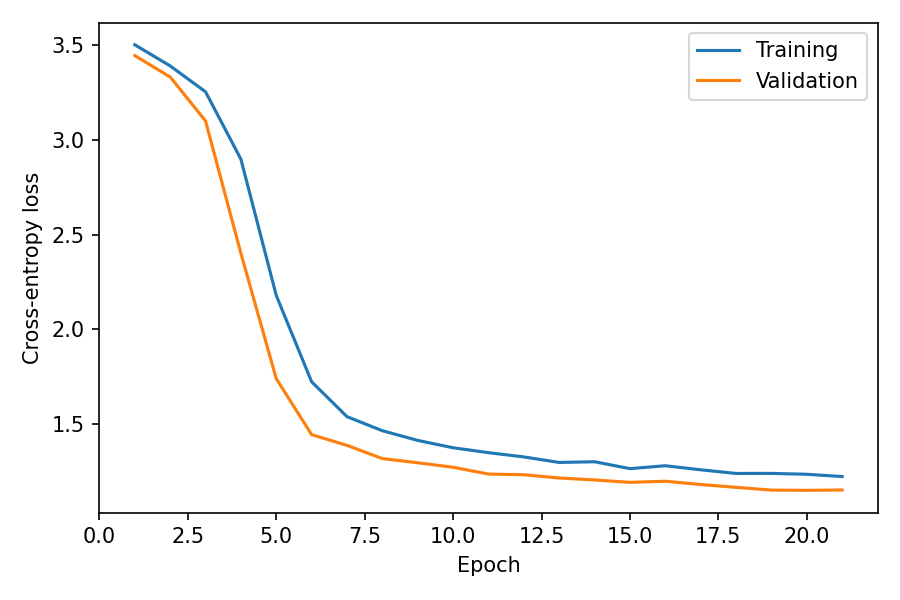

q4_A_aug_only failures:
  val_000001: query K20, gold V19, predicted V21, records=27, stores=2, records with query key: ['NOISE K20 V17', 'STORE K20 V19']
  val_000003: query K1, gold V17, predicted V15, records=24, stores=3, records with query key: ['NOISE K1 V12', 'STORE K1 V17']
  val_000007: query K21, gold V29, predicted V4, records=13, stores=4, records with query key: ['STORE K21 V29']
  val_000008: query K7, gold V9, predicted V10, records=7, stores=2, records with query key: ['STORE K7 V9']
  val_000010: query K1, gold V23, predicted V8, records=19, stores=4, records with query key: ['STORE K1 V23']


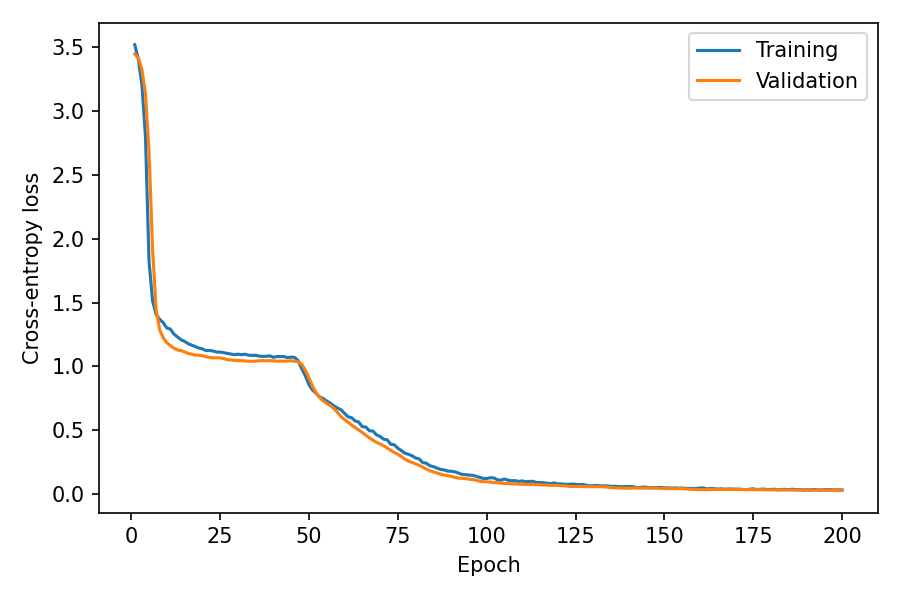

q4_D_d256_n256_L3_qhead failures:
  val_000043: query K11, gold V20, predicted V29, records=15, stores=3, records with query key: ['STORE K11 V20']
  val_000115: query K21, gold V23, predicted V0, records=19, stores=4, records with query key: ['STORE K21 V23']
  val_000166: query K19, gold V1, predicted V6, records=12, stores=4, records with query key: ['STORE K19 V1', 'NOISE K19 V26']
  val_000189: query K11, gold V28, predicted V7, records=8, stores=4, records with query key: ['STORE K11 V28']
  val_000280: query K11, gold V7, predicted V30, records=20, stores=4, records with query key: ['STORE K11 V7']


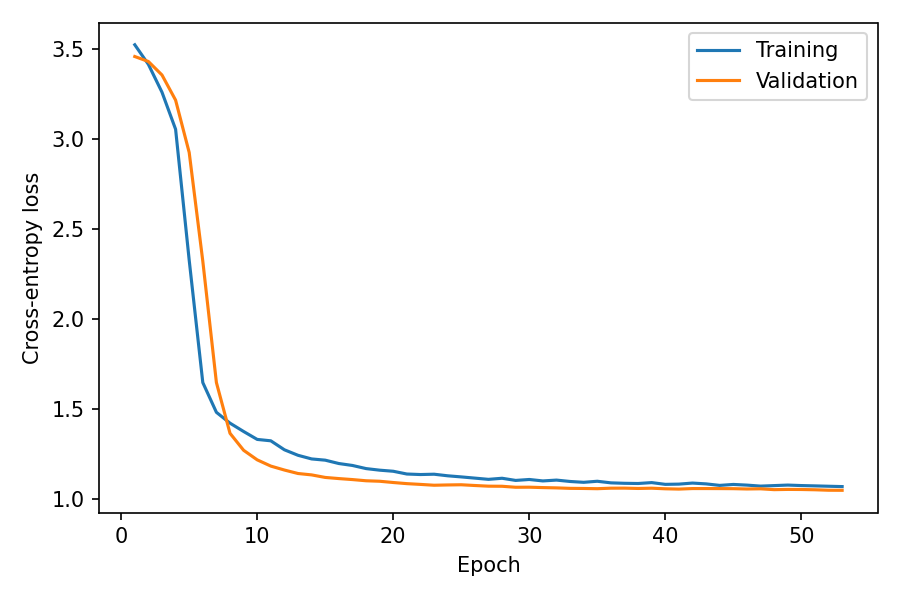

q4_E_d192_n256_L4_qhead failures:
  val_000004: query K31, gold V23, predicted V21, records=18, stores=2, records with query key: ['STORE K31 V23']
  val_000005: query K26, gold V0, predicted V19, records=14, stores=2, records with query key: ['STORE K26 V0', 'NOISE K26 V8']
  val_000007: query K21, gold V29, predicted V26, records=13, stores=4, records with query key: ['STORE K21 V29']
  val_000008: query K7, gold V9, predicted V10, records=7, stores=2, records with query key: ['STORE K7 V9']
  val_000010: query K1, gold V23, predicted V8, records=19, stores=4, records with query key: ['STORE K1 V23']


In [15]:
# Q4(a) comparison with the original gated model (validation only)
rows_q4 = {"Gated SSM (Q2 original)": {
    "Trainable parameters": results["gated"]["summary"]["effective_trainable_parameters"],
    "Best val accuracy": results["gated"]["summary"]["best_validation_accuracy"],
    "Best epoch": results["gated"]["best"]["epoch"],
    "Train s/epoch": results["gated"]["summary"]["mean_train_seconds_per_epoch"],
    "Inference samples/s": results["gated"]["summary"]["inference"]["forward_samples_per_second"],
    "Peak GPU MiB": (results["gated"]["summary"]["peak_training_allocated_bytes"] or 0) / 2**20}}
for name, s in q4_results.items():
    rows_q4[name] = {"Trainable parameters": s["effective_trainable_parameters"],
                     "Best val accuracy": s["best_validation_accuracy"], "Best epoch": s["best_epoch"],
                     "Train s/epoch": s["mean_train_seconds_per_epoch"],
                     "Inference samples/s": s["inference"]["forward_samples_per_second"],
                     "Peak GPU MiB": s["peak_training_allocated_MiB"] or 0}
q4_df = pd.DataFrame(rows_q4).T
display(q4_df.style.format({"Trainable parameters": "{:,.0f}", "Best val accuracy": "{:.4f}", "Best epoch": "{:.0f}",
                            "Train s/epoch": "{:.2f}", "Inference samples/s": "{:,.0f}", "Peak GPU MiB": "{:.1f}"}))
for name in q4_results:
    display(Image(filename=f"runs/{name}/learning_curves.png"))
    print(name, "failures:"); [show_failure(r) for r in json.loads(Path(f"runs/{name}/failure_examples.json").read_text())]


### Q4 ablation
A isolates augmentation (same model as Q2 + augmentation + schedule); D and E add width/state, depth, the query-key head and the long schedule. A vs Q2 shows augmentation alone does not help the small model; D vs E shows that width (d = N = 256) was what let training escape the 0.40 plateau.

## Q4(b) — one final Kaggle submission

Choose your checkpoint using validation. Upload submission.csv manually to the course Kaggle page, use your student ID as team name, and select one final submission. Keep the exact CSV, checkpoint, configuration and Kaggle submission ID for grading. This notebook does not create a competition or upload predictions automatically.

In [16]:
# Select ONE final checkpoint by validation accuracy (ties -> lower validation loss); test labels are never used
best_name = max(q4_results, key=lambda n: (q4_results[n]["best_validation_accuracy"], -q4_results[n]["best_validation_loss"]))
FINAL_CHECKPOINT = Path(f"runs/{best_name}/best.pt")
print("Selected:", best_name, "| val acc", q4_results[best_name]["best_validation_accuracy"])
from hw2_1_q4 import write_submission
write_submission(FINAL_CHECKPOINT, DATA_DIR / "test.jsonl", "submission.csv")
ck = torch.load(FINAL_CHECKPOINT, map_location="cpu", weights_only=True)
print("Model configuration:", ck["config"]); print("Training configuration:", ck["train_config"])
json.dump({"checkpoint": str(FINAL_CHECKPOINT), "model_config": ck["config"], "train_config": ck["train_config"],
           "epoch": ck["epoch"], "validation": ck["validation"]}, open("final_model_config.json", "w"), indent=2)
import pandas as pd; print(pd.read_csv("submission.csv").head()); print(pd.read_csv("submission.csv")["answer"].value_counts().head())


Selected: q4_D_d256_n256_L3_qhead | val acc 0.9913333333333333
Wrote 2000 predictions to submission.csv (checkpoint epoch 198, val acc 0.9913)
Model configuration: {'d': 256, 'n': 256, 'layers': 3, 'dropout': 0.0, 'a_min': 0.01, 'a_max': 0.99, 'head': 'query', 'head_hidden': 256}
Training configuration: {'name': 'q4_D_d256_n256_L3_qhead', 'd': '256', 'n': '256', 'layers': '3', 'dropout': '0.0', 'a_min': '0.01', 'a_max': '0.99', 'head': 'query', 'head_hidden': '256', 'augment': 'True', 'epochs': '200', 'batch_size': '128', 'lr': '0.001', 'weight_decay': '0.01', 'warmup_frac': '0.05', 'min_lr_frac': '0.02', 'eval_every': '1', 'seed': '42', 'patience': '40', 'ema_decay': '0.995', 'data': 'data', 'out': 'runs/q4_D_d256_n256_L3_qhead'}
            id answer
0  test_000001    V31
1  test_000002     V9
2  test_000003     V6
3  test_000004    V27
4  test_000005    V24
answer
V21    79
V24    78
V18    76
V12    73
V25    72
Name: count, dtype: int64


In [17]:
# Bundle everything needed for the course submission (download this zip)
import shutil, zipfile
with zipfile.ZipFile("hw2_1_artifacts.zip", "w") as z:
    for p in ["submission.csv", "final_model_config.json", str(FINAL_CHECKPOINT), "hw2_1.py", "hw2_1_q4.py"] + \
             [str(p) for p in Path("runs").rglob("*") if p.suffix in (".json", ".png", ".pt") and "smoke" not in str(p)]:
        z.write(p)
print("wrote hw2_1_artifacts.zip")
try:
    from google.colab import files; files.download("submission.csv"); files.download("hw2_1_artifacts.zip")
except Exception:
    pass


wrote hw2_1_artifacts.zip


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'runs/q4_D_d256_n256_L3_qhead/best.pt'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Written report (Problem 1)

**Reproducibility.** Seed 42 for every run (`random`, `torch`, CUDA; deterministic cuDNN), FP32. Hardware/software: NVIDIA A100-SXM4-40GB (Google Colab), Python 3.13.16, PyTorch 2.11.0+cu130 (CUDA 13.0), Matplotlib 3.10.0. Q1–Q3 use exactly the provided settings: embedding → 2 pre-LN SSM blocks (d = N = 64, dropout 0.1) → LayerNorm → 32-way head, AdamW (lr 1e-3, weight decay 0.01), batch 64, 10 epochs, gradient clipping 1.0. Initialisation (same rule for the shared parameter types of both models): a = σ(θ_a) evenly spaced over [0.5, 0.99]; B, C, D, W_g ~ N(0, 1/fan_in); gate bias b_g = 0. No adjustments to the prescribed settings were made for Q1–Q3.

### Q1 — Basic SSM

Best validation accuracy: **0.1913 at epoch 10** (validation loss 2.858). Curves: `runs/basic/learning_curves.png` (shown above).

**Q1(c) Implementation and discussion.** The block input x ∈ ℝ^{batch×L×d} is LayerNorm-ed per position. `basic_forward` computes a = σ(θ_a) ∈ (0,1)^N, the input projection u_t = B x_t (batch×L×N), the recurrence h_t = a ⊙ h_{t−1} + u_t with h_0 = 0, and the output y_t = C h_t + D x_t (batch×L×d); B, C, D have no bias. The recurrence is evaluated with a parallel (Hillis–Steele) prefix scan over time: in log₂L rounds position t is combined with position t−2^k. This is exactly the sequential recurrence (the check cell compares it with a literal loop of the PDF equations: max error 1.1e-6) and strictly causal (changing tokens after t leaves outputs ≤ t unchanged: `True`). The state is never stored on the module: every forward call starts from h_0 = 0 for each sample and each layer, so nothing carries across batches (`stateless across calls: True`). With right padding all PAD tokens come *after* the ANSWER token, so by causality they cannot influence it; the model reads the representation at index `lengths − 1` (the last real token = ANSWER), not the last padded column (`padding-safe ANSWER selection: True`).

Loss curves: training loss falls slowly and almost linearly from 3.49 to 2.73 and validation loss from 3.45 to 2.86, with validation accuracy still rising every epoch (0.045 → 0.191). Both curves are still decreasing at epoch 10 and the gap is small, so the basic model is clearly **under-fitted, not over-fitted**: 10 epochs are not enough, and more fundamentally a fixed decay a writes STORE and NOISE records with the same weight and lets old STORE values decay exponentially, so the model has no mechanism to keep only valid pairs.

### Q2 — Gated SSM

Best validation accuracy: **0.4060 at epoch 8** (validation loss 1.404). Curves: `runs/gated/learning_curves.png`.

**Q2(c) Implementation and discussion.** `gate_compute` evaluates g_t = σ(W_g x_t + b_g) ∈ (0,1)^N at every position from the LayerNorm-ed current input. `gate_forward` forms the candidate h̃_t = a ⊙ h_{t−1} + B x_t and mixes h_t = (1 − g_t) ⊙ h_{t−1} + g_t ⊙ h̃_t. This is algebraically the linear recurrence h_t = (1 − g_t(1 − a)) ⊙ h_{t−1} + g_t ⊙ B x_t, so the same parallel scan is used with a *time-varying* decay λ_t = 1 − g_t(1 − a) and input g_t ⊙ B x_t (matches the literal PDF loop: max error 9.5e-7). When g_t ≈ 0 a channel ignores the current token and copies its state unchanged (perfect retention, no decay); when g_t ≈ 1 it performs the full basic update (decay by a and write B x_t; with small a this is an overwrite). The model can therefore write *selectively*.

Gating clearly helped: 0.406 vs 0.191 validation accuracy and 1.40 vs 2.86 validation loss under identical settings. The curves show a fast drop between epochs 3 and 5 (val acc 0.19 → 0.39) followed by a plateau around 0.38–0.41; train loss (1.25) and validation loss (1.38) stay close, so there is at most mild over-fitting. The failure cases explain the plateau: the gated model almost always predicts a value that **was stored** (it learned to ignore NOISE records), but often the value of a *different* STORE key. Guessing uniformly among the 2–4 stored values would give (1/2 + 1/3 + 1/4)/3 ≈ 0.36, very close to the observed 0.39–0.41. So gating solves the "ignore noise" part, but the small model has not learned to **bind** each value to its key.

### Q3 — Comparison

| Metric | Basic SSM | Gated SSM |
|---|---|---|
| Trainable parameters | 31,712 | 40,032 |
| Validation accuracy | 0.1913 (epoch 10) | 0.4060 (epoch 8) |
| Training time (seconds/epoch) | 2.24 | 2.47 |
| Inference throughput (samples/s) | 30,696 | 27,129 |
| Peak GPU allocated memory (MiB) | 92.5 | 104.8 |

Hardware/software: NVIDIA A100-SXM4-40GB, PyTorch 2.11.0+cu130, Python 3.13.16, FP32. Inference scope: first validation batch, batch size 64, padded length 124, 3 warm-up + 10 timed forwards.

**Q3(b) Implementation and discussion.** Both models were trained with the same script, GPU, FP32 precision, batch size 64 and data order (seed 42). Training time is the mean over epochs of the training loop only, with `torch.cuda.synchronize()` before starting and before stopping the timer, excluding validation and plotting. Throughput uses the selected checkpoint in `eval()` mode under `no_grad` on a fixed validation batch already on the GPU (transfers excluded): 3 warm-up forwards (kernel selection, memory allocation), then 10 timed forwards between two synchronisations; samples/s = 64 / mean forward time. Peak memory is `torch.cuda.max_memory_allocated` during training, in MiB.

Trade-off: the gated model has 26% more parameters (an extra W_g ∈ ℝ^{N×d} and b_g per layer) and an extra matmul + sigmoid per layer, so it is about 10% slower per training epoch (2.47 vs 2.24 s), has 12% lower inference throughput (27.1k vs 30.7k samples/s) and uses 13% more peak memory (the gate tensor g ∈ ℝ^{B×L×N} must be stored for backpropagation). In exchange it more than doubles validation accuracy, so it is the better accuracy–cost trade-off. Possible reasons for the accuracy difference: (1) **mechanism** – the input-dependent gate can skip NOISE records and hold stored information without decay, which a fixed a cannot; (2) **parameter count** – the gated model has more capacity, so part of the gain may come from extra parameters rather than gating itself; (3) **training randomness and budget** – one seed and 10 epochs only: the basic model is still improving at epoch 10 and the gated model's accuracy fluctuates between 0.37 and 0.41 after epoch 5, so a few points of difference are within run-to-run noise. Runtime differences are partly kernel-launch overhead, which dominates for tensors this small.

Representative failure cases (cell above):
* `val_000001` (query K20, gold V19): basic predicts V29, gated predicts V21; the prompt also contains `NOISE K20 V17` before the valid `STORE K20 V19`, yet neither model outputs the noise value — the failure is retrieval, not noise.
* `val_000002` (query K23, gold V23, 4 STORE records): gated predicts V17, the value of the *other* stored key K16 (`STORE K16 V17`) → key–value binding failure.
* `val_000003` (query K1, gold V17): basic predicts V15, the value of `STORE K9 V15` → the model remembers stored values but not which key they belong to.
* `val_000006` (query K5, gold V21, two `NOISE K5` distractors): gated predicts V4, the value of `STORE K7 V4` — it ignored both noise values for K5 but returned another stored value.

### Q4(a) — Improvement and validation results

Changes (all keep the prescribed `GatedDiagonalSSM` update equations, token-only inputs, train-only optimisation and fewer than 10⁶ trainable parameters):

1. **Task-consistent augmentation of `train.jsonl` only** (re-drawn every time a sample is loaded): consistent random renaming of all keys (permutation of K0–K31) and of all values (permutation of V0–V31, label mapped accordingly), random shuffle of record order (the task states record order is random), and a re-sampled query among the valid STORE keys with the recomputed label. Every original and augmented training sample is checked by `check_sample` (format valid, STORE keys distinct, label = STORE value of the query key).
2. **Larger state, width and depth**: d = 256, N = 256, 3 layers (model D) and d = 192, N = 256, 4 layers (model E).
3. **Prediction head** combining the final ANSWER representation r with the embedding e_q of the observed query key: logits = W r + b + W₃((W₁ r) ⊙ (W₂ e_q)).
4. **Training schedule**: up to 200 epochs (A: 30), batch 128, AdamW lr 1e-3 (A: 1e-3, batch 64), linear warm-up (5%) + cosine decay, dropout 0, decay initialisation widened to a ∈ [0.01, 0.99] (small a allows overwrite-type updates when g ≈ 1), an exponential moving average of the weights (decay 0.995; still a single model) used for validation and checkpointing, and early stopping after 40 epochs without validation improvement.

| Model | Params | Best val acc | Best epoch | Train s/epoch | Inference samples/s | Peak GPU MiB |
|---|---|---|---|---|---|---|
| Gated SSM (Q2 original) | 40,032 | 0.4060 | 8 | 2.47 | 27,129 | 104.8 |
| A: Q2 model + augmentation, 30 ep | 40,032 | 0.4067 | 11 | 3.10 | 27,096 | 105.0 |
| **D: d256 N256 L3 + query head** | **955,680** | **0.9913** | **198** | 3.34 | 17,400 | 1041.5 |
| E: d192 N256 L4 + query head | 867,552 | 0.4053 | 13 | 3.72 | 13,230 | 1305.6 |

(Q4 epochs use batch 128 with on-the-fly augmentation in Python, so seconds/epoch are not directly comparable with Q2's batch 64; the inference benchmark uses the same batch-64 protocol for all models.)

### Q4(b) — Kaggle submission

* Team name: `315511079`
* Final selected model: D (`runs/q4_D_d256_n256_L3_qhead/best.pt`, epoch 198, validation accuracy 0.9913)
* Final selected Kaggle submission: `submission (20).csv` (team 315511079, submitted 2026-10-24, marked as the final submission; the Kaggle UI does not display a numeric submission ID — see the screenshot below)
* Public score: **0.99500** (Private score is revealed after the deadline)

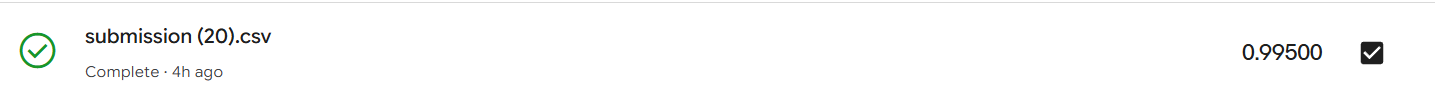

* Files: `submission.csv`, `final_model_config.json`, checkpoint `runs/q4_D_d256_n256_L3_qhead/best.pt`, code `hw2_1.py`, `hw2_1_q4.py` (all in `hw2_1_artifacts.zip`).

### Q4(c) — Implementation and discussion

**What and why.** Q2 showed that the gated model learns to ignore noise but plateaus at ≈ 0.40 because it does not bind values to keys. Solving the task needs (i) a key-addressed *write* — store the value of a STORE record in state associated with its key — and (ii) a key-addressed *read* at the ANSWER position. In the gated SSM the gate g_t multiplies the write B x_t, so a state channel can be opened only for "value token of a STORE record whose key is k". Layer 1 carries the record marker and key forward to the value position (gate open on the marker/key token, then closed). This gives a multiplicative, key-selective write, but it needs many state channels (32 possible keys × a few channels per value code). We therefore enlarged N to 256 and d to 256 so the residual stream at the ANSWER position can carry the memory to the head. The read uses the allowed query-key head, whose element-wise product (W₁ r) ⊙ (W₂ e_q) lets the query key select the matching part of the memory. Augmentation targets data efficiency: 12,000 prompts are few for a combinatorial task, and key/value renaming forces the model to learn the rule instead of token-specific statistics, while re-querying and record shuffling generate unlimited correctly labelled prompts from `train.jsonl` only.

**Effect (validation).**
* Augmentation alone on the small Q2 model (A) did not help (0.4067 vs 0.4060). The bottleneck of the small model is capacity/binding, not data.
* The wide model D reached **0.9913** validation accuracy, +58.5 points over the original gated model, at 24× the parameters (955,680, still below 10⁶), 1.6× lower inference throughput and ≈ 10× peak training memory. Its best epoch (198 of 200) shows that long training with fresh augmented data was necessary.
* The deeper but narrower model E stayed on the same ≈ 0.40 "pick one of the stored values" plateau (best 0.4053 at epoch 13) and was stopped by early stopping. This illustrates that escaping the plateau is an optimisation event that depends on width and on training randomness (initialisation/seed): with d = 192 the residual stream is narrower than the state (N = 256), and this run never found the key–value binding solution within the budget.
* The remaining errors of D occur mostly on prompts with 4 STORE records, where four key–value pairs must be kept apart in the same state.

**Checkpoint selection and CSV.** Each run saves the epoch with the highest validation accuracy (ties → lower validation loss), evaluated with the EMA weights. Across candidates the run with the highest validation accuracy (D) was selected automatically. `test.jsonl` has no labels and was used only once, at the very end, to write predictions with the selected checkpoint: argmax over V0–V31, columns `id,answer`, every test id exactly once and in order (asserted by `write_submission`). Neither validation nor test data was used for training or augmentation, and the public leaderboard was not used for model selection.
